# Customer Feedback Analysis and Automated Response

## Final Capstone Notebook

**Domain:** Online-retail consumer electronics customer reviews  
**Primary tools:** Python, Pandas, Matplotlib, Google GenAI API  
**Project type:** Rule-based customer-feedback triage with GenAI response drafting

### Submission objective

This notebook is the complete, transparent implementation of the assessment workflow. Every major decision is shown in the notebook instead of being hidden inside pre-generated results.

```text
Raw dataset
    ↓
Data loading
    ↓
Data profiling
(shape / info / describe)
    ↓
Data audit
(missing values / duplicates / invalid values)
    ↓
Preprocessing
    ↓
EDA on the target variable: rating
    ↓
Critical filtering
(1-star and 2-star)
    ↓
Rule-based complaint analysis
    ↓
Top 3 Critical review selection
    ↓
Gemini API key input (hidden)
    ↓
3 live Gemini response drafts
    ↓
Interactive review selection (1–3)
+ optional additional customer comment
    ↓
One additional Gemini response draft
```

**Important:** Gemini does not decide which reviews are Critical. Python performs the analytical decisions. Gemini is used for natural-language response drafting only. No email is sent automatically.

## 1. Business problem and assessment mapping

A retail support team receives many customer reviews. Manually reading every review and identifying urgent complaints is time-consuming.

This project addresses the first part of that workflow by:

1. Loading and auditing customer-review data.
2. Cleaning the data without overwriting the raw source.
3. Using the rating as the target variable for a small descriptive EDA.
4. Defining **Critical** feedback transparently as 1-star or 2-star reviews.
5. Identifying complaint categories with a human-defined rule dictionary and `Counter`.
6. Selecting three detailed Critical reviews using a deterministic priority rule.
7. Sending only those selected review contexts to Gemini to draft empathetic response emails.
8. Providing an interactive demonstration where a reviewer selects case 1, 2, or 3 and optionally adds another customer comment.

The project deliberately does **not** use a machine-learning classifier because the assessment asks for rule-based filtering and complaint analysis.

In [1]:
from pathlib import Path
import re
from collections import Counter
from getpass import getpass

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

possible_paths = [
    Path("data/raw/amazon_electronics_reviews.csv"),
    Path("amazon_electronics_reviews.csv"),
]
RAW_PATH = next((path for path in possible_paths if path.exists()), None)
if RAW_PATH is None:
    raise FileNotFoundError(
        "Dataset not found. Place amazon_electronics_reviews.csv in data/raw/ "
        "or beside this notebook."
    )

print("Raw dataset found at:", RAW_PATH)


Raw dataset found at: amazon_electronics_reviews.csv


## 2. Load the raw dataset

The raw CSV is treated as the source of truth. It is not overwritten.

**Dataset source:** Mendeley Data, *sentiment in customer reviews*.  
Source page: https://data.mendeley.com/datasets/2zfbcy96vp/1

The working file contains 3,600 consumer-electronics reviews and 11 raw columns.

In [2]:
raw = pd.read_csv(RAW_PATH, low_memory=False)

print("Shape:", raw.shape)
print("\nColumns:")
print(raw.columns.tolist())

Shape: (3600, 11)

Columns:
['Unnamed: 0', 'product', 'title', 'author', 'date', 'ver.purchase', 'format', 'stars', 'comments', 'helpful', 'type']


## 3. Raw-data profiling

Before changing anything, we inspect the structure and basic statistics.

The purpose is to make preprocessing decisions from evidence rather than assumptions.

In [3]:
print("### HEAD")
display(raw.head())

print("\n### INFO")
raw.info()

print("\n### DESCRIBE")
display(raw.describe(include="all").T)

### HEAD


,Unnamed: 0,product,title,author,date,ver.purchase,format,stars,comments,helpful,type
0,1,galaxyon7,Beautiful premium metallic design,D O L L Y 👑 ( IIM A),3 February 2018,1,Size: 32GB,5,I have used this phone almost a month. So I wa...,60.0,1
1,2,galaxyon7,Budget phone But Could Have Been Better!,Dr Harshit Saxena,24 January 2018,1,Size: 64GB,4,Hello Samsung Lovers!This phone looks beautifu...,107.0,1
2,3,galaxyon7,Another Failed Attempt by Samsung!,Vinay Arora,7 March 2018,0,Size: 32GB,1,"Well, when I started reviewing the Galaxy On7 ...",21.0,1
3,4,galaxyon7,My mobile headset is not recived i was return ...,sekhar.nallagulla,4 February 2018,1,Size: 64GB,1,My mobile headset is not recived i was retur...,3.0,1
4,5,galaxyon7,Good Mid Budget Smartphone,Harsh Singhal,27 February 2018,1,Size: 32GB,5,A Good Mid budget phone..1. Display: With a Sa...,8.0,1



### INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3600 entries, 0 to 3599
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0    3600 non-null   int64  
 1   product       3600 non-null   object 
 2   title         3600 non-null   object 
 3   author        3599 non-null   object 
 4   date          3600 non-null   object 
 5   ver.purchase  3600 non-null   int64  
 6   format        2696 non-null   object 
 7   stars         3600 non-null   int64  
 8   comments      3575 non-null   object 
 9   helpful       2315 non-null   float64
 10  type          3600 non-null   int64  
dtypes: float64(1), int64(4), object(6)
memory usage: 309.5+ KB

### DESCRIBE


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,3600.0,NaN,NaN,NaN,1800.5,1039.374812,1.0,900.75,1800.5,2700.25,3600.0
product,3600,12,galaxyon7,300,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,3600,2649,Five Stars,349,NaN,NaN,NaN,NaN,NaN,NaN,NaN
author,3599,2584,Amazon Customer,702,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date,3600,500,25 January 2018,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ver.purchase,3600.0,NaN,NaN,NaN,0.97,0.170611,0.0,1.0,1.0,1.0,1.0
format,2696,20,Colour: Black,750,NaN,NaN,NaN,NaN,NaN,NaN,NaN
stars,3600.0,NaN,NaN,NaN,3.927222,1.432459,1.0,3.0,5.0,5.0,5.0
comments,3575,3337,Good,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
helpful,2315.0,NaN,NaN,NaN,4.805184,15.192188,1.0,1.0,2.0,3.0,351.0


## 4. Data audit

The audit checks:

- Missing values
- Exact duplicate rows
- Review-level duplicate candidates
- Rating validity
- Empty review text
- Basic text length

A review-level duplicate candidate is **not automatically deleted**. The same rating and text can legitimately occur for different products/customers. Therefore, only exact duplicate rows are treated as true duplicates here.

In [4]:
missing_report = raw.isna().sum().sort_values(ascending=False).to_frame("missing_count")
missing_report["missing_percent"] = (missing_report["missing_count"] / len(raw) * 100).round(2)
display(missing_report)

exact_duplicates = int(raw.duplicated().sum())
review_key_duplicates = int(raw.duplicated(subset=["stars", "comments"]).sum())
invalid_ratings = int((raw["stars"].isna() | ~raw["stars"].between(1, 5)).sum())
empty_comments = int(raw["comments"].fillna("").astype(str).str.strip().eq("").sum())

print("Exact duplicate rows:", exact_duplicates)
print("Review-level duplicate candidates (stars + comments):", review_key_duplicates)
print("Invalid or missing ratings:", invalid_ratings)
print("Missing/empty review text:", empty_comments)
print("Unique ratings:", sorted(raw["stars"].dropna().unique().tolist()))

,missing_count,missing_percent
helpful,1285,35.69
format,904,25.11
comments,25,0.69
author,1,0.03
Unnamed: 0,0,0.00
product,0,0.00
title,0,0.00
date,0,0.00
ver.purchase,0,0.00
stars,0,0.00


Exact duplicate rows: 0
Review-level duplicate candidates (stars + comments): 249
Invalid or missing ratings: 0
Missing/empty review text: 25
Unique ratings: [1, 2, 3, 4, 5]


### Audit decision

For this dataset:

- There are **0 exact duplicate rows**.
- There are **0 invalid or missing ratings**.
- There are **25 missing/empty review-text values**.
- There are **249 review-level duplicate candidates** based only on `(stars, comments)`. These are retained because that key alone does not prove that two customer records are duplicates.
- The source index column `Unnamed: 0` is an import artifact and is removed from the derived dataset.

This is an important distinction: **audit results are reported even when the correct action is to keep the records.**

## 5. Data preprocessing

The preprocessing creates a new analysis dataset. The raw CSV remains unchanged.

### Decisions

- Rename source columns into analysis-friendly names.
- Remove only the source index artifact `Unnamed: 0`.
- Convert the rating to numeric and validate the 1–5 range.
- Preserve the original customer review in `review_text_original`.
- Create `review_text_clean` for rule-based analysis.
- Keep missing review-text rows but flag them.
- Parse the review date.
- Calculate review word count.
- Create a stable `review_id`.

The original review text is preserved because it is needed later for auditability and for Gemini response drafting.

In [5]:
processed = raw.copy()

rename_map = {
    "product": "product",
    "title": "title",
    "author": "author",
    "date": "review_date",
    "ver.purchase": "verified_purchase",
    "format": "product_format",
    "stars": "rating",
    "comments": "review_text_original",
    "helpful": "helpful_votes",
    "type": "source_type",
}

processed = processed.drop(columns=["Unnamed: 0"])
processed = processed.rename(columns=rename_map)

processed["rating"] = pd.to_numeric(processed["rating"], errors="coerce")

# The audit showed no invalid ratings, but we keep the validation explicit.
processed = processed[processed["rating"].between(1, 5)].copy()

processed["review_text_missing"] = processed["review_text_original"].isna()


def clean_review_text(value):
    if pd.isna(value):
        return ""
    text = str(value).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


processed["review_text_clean"] = processed["review_text_original"].apply(clean_review_text)
processed["review_length_words"] = processed["review_text_clean"].str.split().str.len()
processed["review_date"] = pd.to_datetime(processed["review_date"], errors="coerce")
processed["review_id"] = [f"REV-{i:05d}" for i in range(1, len(processed) + 1)]

print("Processed shape:", processed.shape)
display(processed[[
    "review_id", "product", "rating", "review_text_original",
    "review_text_clean", "review_text_missing", "review_length_words"
]].head())

Processed shape: (3600, 14)


,review_id,product,rating,review_text_original,review_text_clean,review_text_missing,review_length_words
0,REV-00001,galaxyon7,5,I have used this phone almost a month. So I wa...,i have used this phone almost a month so i wan...,False,518
1,REV-00002,galaxyon7,4,Hello Samsung Lovers!This phone looks beautifu...,hello samsung lovers this phone looks beautifu...,False,409
2,REV-00003,galaxyon7,1,"Well, when I started reviewing the Galaxy On7 ...",well when i started reviewing the galaxy on7 p...,False,1568
3,REV-00004,galaxyon7,1,My mobile headset is not recived i was retur...,my mobile headset is not recived i was return ...,False,13
4,REV-00005,galaxyon7,5,A Good Mid budget phone..1. Display: With a Sa...,a good mid budget phone 1 display with a samsu...,False,246


### Preprocessing result

No customer-review rows are removed because the audit found no invalid ratings and no exact duplicate rows. Missing review text is retained and flagged rather than silently discarded.

This preserves the natural structure of the source data and keeps the cleaning decisions auditable.

## 6. Exploratory Data Analysis — target variable

The main target variable for this project is **`rating`** because the business rule uses customer rating to define Critical feedback.

The EDA is intentionally small and focused:

> **What does the rating distribution tell us before we create the Critical queue?**

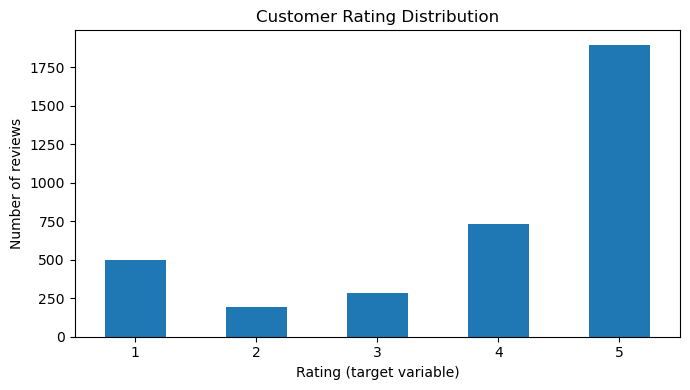

Average rating: 3.93
Median rating: 5
1–2 star share: 19.08%
4–5 star share: 72.94%


In [6]:
rating_counts = processed["rating"].value_counts().sort_index()

plt.figure(figsize=(7, 4))
rating_counts.plot(kind="bar")
plt.title("Customer Rating Distribution")
plt.xlabel("Rating (target variable)")
plt.ylabel("Number of reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

total = len(processed)
critical_preview = processed["rating"].isin([1, 2]).mean() * 100
positive_preview = processed["rating"].isin([4, 5]).mean() * 100

print(f"Average rating: {processed['rating'].mean():.2f}")
print(f"Median rating: {processed['rating'].median():.0f}")
print(f"1–2 star share: {critical_preview:.2f}%")
print(f"4–5 star share: {positive_preview:.2f}%")

### EDA inference

The rating distribution is strongly concentrated toward positive ratings: 4- and 5-star reviews make up most of the dataset, while 1- and 2-star reviews form a smaller but operationally important group.

Therefore, the next business step is not to treat the entire dataset as equally urgent. We create a transparent Critical queue from the 1- and 2-star reviews so the support team can focus attention on the most negative feedback first.

**Important limitation:** this EDA is descriptive. The rating distribution alone does not prove why a customer was dissatisfied or which product feature caused the problem.

## 7. Rule-based Critical filtering

The assessment defines the Critical queue using a simple, auditable rule:

```python
Critical = rating <= 2
```

No machine-learning classifier is used.

In [7]:
critical = processed[processed["rating"] <= 2].copy()

print("Total reviews:", len(processed))
print("Critical reviews:", len(critical))
print("Critical rate: {:.2f}%".format(len(critical) / len(processed) * 100))
print("\nCritical rating counts:")
print(critical["rating"].value_counts().sort_index())

Total reviews: 3600
Critical reviews: 687
Critical rate: 19.08%

Critical rating counts:
rating
1    495
2    192
Name: count, dtype: int64


## 8. Rule-based complaint analysis

The complaint dictionary is deliberately transparent. It maps customer-language terms to internal categories. Python scans each Critical review and records each category at most once per review.

This is **rule-based text analysis, not sentiment analysis and not machine learning**.

In [8]:
COMPLAINT_DICTIONARY = {
    "battery": ["battery", "battery life", "battery backup", "drains", "drain", "backup"],
    "charging": ["charge", "charging", "charger", "charging port", "slow charge", "fast charge"],
    "heating": ["heat", "heating", "overheat", "overheating", "hot"],
    "camera": ["camera", "photo", "picture", "pictures", "image", "images", "flash"],
    "display": ["screen", "display", "brightness", "touchscreen", "touch screen", "pixels"],
    "audio": ["sound", "speaker", "speakers", "volume", "audio", "headphone", "earphone"],
    "connectivity": ["wifi", "wi fi", "bluetooth", "network", "signal", "connection", "connect"],
    "software": ["software", "app", "apps", "android", "update", "lag", "lags", "slow", "crash", "hang"],
    "quality_or_damage": ["broken", "defect", "defective", "poor quality", "cheap quality", "damaged", "damage", "faulty", "stopped working", "not working"],
    "delivery_or_packaging": ["delivery", "delivered", "package", "packaging", "box", "shipping", "late", "missing item"],
    "value_or_expectation": ["price", "expensive", "worth", "waste", "disappointed", "expect", "expectation"],
}


def find_matching_categories(text):
    text = str(text)
    matches = []
    for category, terms in COMPLAINT_DICTIONARY.items():
        if any(term in text for term in terms):
            matches.append(category)
    return matches


critical["complaint_categories"] = critical["review_text_clean"].apply(find_matching_categories)
critical["complaint_category_count"] = critical["complaint_categories"].str.len()
critical["complaint_categories_text"] = critical["complaint_categories"].apply(
    lambda values: ", ".join(values) if values else "No matched category"
)

category_counter = Counter(
    category
    for categories in critical["complaint_categories"]
    for category in set(categories)
)

category_counts = pd.DataFrame(
    category_counter.items(), columns=["category", "critical_review_count"]
).sort_values("critical_review_count", ascending=False)

print("Critical reviews with at least one matched category:", int((critical["complaint_category_count"] > 0).sum()))
display(category_counts)

Critical reviews with at least one matched category: 617


,category,critical_review_count
3,audio,258
0,software,229
10,quality_or_damage,180
4,value_or_expectation,167
5,connectivity,134
8,battery,111
2,charging,107
6,camera,107
1,display,80
9,heating,77


### Complaint-analysis inference

The category counts show which complaint themes appear most often in the Critical queue. Because one review can contain several complaint categories, category totals are **not expected to add up to the number of Critical reviews**.

The method is intentionally simple and auditable. Its main limitation is that literal keyword rules can miss synonyms, spelling variations, context, negation, sarcasm, or complaints expressed without any dictionary term.

## 9. Select the top 3 Critical reviews

The assignment asks for three of the most critical and detailed negative reviews. To make that phrase reproducible, the notebook uses this deterministic priority order:

1. Lower rating first.
2. More matched complaint categories next.
3. Longer review next.
4. `review_id` as a stable final tie-breaker.

A long review is **not** automatically considered more urgent; length is only a secondary detail signal after severity and complaint breadth.

In [9]:
priority = (
    critical
    .sort_values(
        ["rating", "complaint_category_count", "review_length_words", "review_id"],
        ascending=[True, False, False, True],
    )
    .head(3)
    .copy()
)

priority["priority_rank"] = range(1, len(priority) + 1)
priority["case_id"] = [f"ELEC-{i:03d}" for i in priority["priority_rank"]]

priority_view = priority[[
    "priority_rank", "case_id", "review_id", "product", "rating",
    "review_length_words", "complaint_category_count", "complaint_categories_text",
    "review_text_original"
]]

display(priority_view)

,priority_rank,case_id,review_id,product,rating,review_length_words,complaint_category_count,complaint_categories_text,review_text_original
2,1,ELEC-001,REV-00003,galaxyon7,1,1568,10,"battery, charging, heating, camera, display, a...","Well, when I started reviewing the Galaxy On7 ..."
1411,2,ELEC-002,REV-01412,lenovok8note,1,298,9,"battery, charging, heating, camera, display, a...",Been using this device for last 90 days or so ...
1263,3,ELEC-003,REV-01264,lenovok8note,1,266,9,"battery, charging, heating, camera, display, a...",Lenovo K6 power is better in many ways than th...


## 10. Gemini API setup — hidden API-key input

The API key is requested **at runtime** using `getpass`. The typed key is not echoed into the notebook output, is not printed, and is not written into the notebook source.

The key stays in memory only for the API call. After the client is created, the local variable containing the key is deleted.

**Do not paste a real key into a code cell.**

In [10]:
GEMINI_MODEL = "gemini-3.5-flash-lite"

print("Gemini model:", GEMINI_MODEL)
print("Enter your API key only when you are ready to make the live API call.")
print("The input is hidden and the key is not printed or saved in this notebook.")

Gemini model: gemini-3.5-flash-lite
Enter your API key only when you are ready to make the live API call.
The input is hidden and the key is not printed or saved in this notebook.


### Live API key input

Run the next cell when you are ready for the real Gemini generation. The input field will not display the key characters.

In [11]:
from google import genai   #put ur own   - API key

api_key = getpass("Enter Gemini API key (input hidden):
if not api_key.strip():
    raise ValueError("An API key is required for live Gemini generation.")

client = genai.Client(api_key=api_key.strip())
del api_key

print("Gemini client created successfully. The entered key is not displayed.")

Enter Gemini API key (input hidden):  ········


Gemini client created successfully. The entered key is not displayed.


## 11. Gemini prompt and 3 live response drafts

Python has already made the analytical decisions. Gemini receives:

- The selected review's original customer text.
- The matched complaint categories as internal guidance.

The prompt tells Gemini to use the original review as the source of truth and not invent customer names, order numbers, refunds, replacements, policies, tracking information, deadlines, or completed actions.

The output is a **draft only**. No email is sent.

In [12]:
def build_gemini_prompt(row):
    review = str(row.get("review_text_original", "")).strip()
    categories = str(row.get("complaint_categories_text", "the concerns described in the review"))

    return f"""Act as a professional customer-support agent for an online consumer-electronics retailer.
Write one short, empathetic apology-email draft based only on the customer review below.

Requirements:
- Include a clear subject line.
- Address the actual complaint using natural customer-friendly language.
- Keep the email under 120 words.
- Use these complaint categories only as internal guidance: {categories}.
- The original customer review is the source of truth.
- Never copy internal category names, labels, scores, rankings, or analysis terminology into the email.
- If a category is not clearly supported by the original review, do not mention it.
- Do not invent a customer name, order number, refund, replacement, discount, policy, tracking number, deadline, or completed action.
- Ask the customer to contact the retailer's customer-support team with order details for investigation.
- This is a draft for human review; do not claim that any action has already happened.
- Do not use Markdown formatting such as bold text or bullet points inside the email.
- Keep the tone professional, empathetic, concise, and human.

Customer review:
{review}
"""


gemini_drafts = []
for _, row in priority.iterrows():
    response = client.models.generate_content(
        model=GEMINI_MODEL,
        contents=build_gemini_prompt(row),
    )
    draft = (response.text or "").strip()
    if not draft:
        raise RuntimeError(f"Gemini returned an empty draft for {row['case_id']}.")
    gemini_drafts.append(draft)

print(f"Gemini generated {len(gemini_drafts)} live drafts.")

for (_, row), draft in zip(priority.iterrows(), gemini_drafts):
    print(f"\n--- {row['case_id']} | {row['product']} | {int(row['rating'])}-star ---\n")
    print(draft)

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


Gemini generated 3 live drafts.

--- ELEC-001 | galaxyon7 | 1-star ---

Subject: Regarding your recent Samsung Galaxy On7 Prime experience

Dear Customer,

Thank you for sharing your feedback with us regarding the Samsung Galaxy On7 Prime. We are truly sorry to hear that your experience with the device did not meet your expectations, particularly regarding the display quality, rear camera performance, and overall design. We completely understand your concerns about how the phone compares to other options on the market. 

We would love to look into this further for you. Please reach out to our customer support team with your order details so we can investigate this matter and assist you properly. 

Warm regards,

Customer Support Team

--- ELEC-002 | lenovok8note | 1-star ---

Subject: Regarding your recent device experience

Dear Customer,

Thank you for sharing such a detailed review of your device. I am truly sorry to hear that you have experienced issues with the rear camera perform

## 12. Interactive evaluation: enter a new customer review

This cell tests the workflow on a new review supplied by the evaluator.

The evaluator enters:

1. A whole-number customer rating from 1 to 5.
2. A customer comment of any reasonable length.

The notebook rejects blank input, decimal values, non-numeric values, and ratings outside 1–5. Gemini then creates a new apology-email draft using the rating and comment.


In [13]:
while True:
    rating_text = input("Enter the customer rating (1-5): ").strip()
    try:
        user_rating = int(rating_text)
        if 1 <= user_rating <= 5:
            break
        print("Invalid rating. Enter only 1, 2, 3, 4, or 5.")
    except ValueError:
        print("Invalid rating. Enter a whole number from 1 to 5.")

user_comment = input("Enter the customer review comment: ").strip()
if not user_comment:
    raise ValueError("Customer review comment cannot be empty.")

print("\nCustomer rating:", user_rating)
print("Customer comment:")
print(user_comment)


Enter the customer rating (1-5):  3
Enter the customer review comment:  Product was good but battery drains fast except that other all great just improve the battery life



Customer rating: 3
Customer comment:
Product was good but battery drains fast except that other all great just improve the battery life


In [14]:
interactive_prompt = f"""Act as a professional customer-support agent for an online consumer-electronics retailer.
Create one short, empathetic apology-email draft for this new customer review.

Rules:
- Include a clear subject line.
- Address the actual complaint in the customer comment.
- Keep the email under 120 words.
- Use a polite, professional, and human tone.
- Do not invent a customer name, order number, refund, replacement, discount, policy, tracking number, deadline, or completed action.
- Ask the customer to contact the retailer's customer-support team with order details for investigation.
- This is a draft for human review. Do not claim that any action has already happened.
- Do not use Markdown formatting inside the email.

Customer rating: {user_rating} star(s)
Customer comment:
{user_comment}
"""

interactive_response = client.models.generate_content(
    model=GEMINI_MODEL,
    contents=interactive_prompt,
)

interactive_draft = (interactive_response.text or "").strip()
if not interactive_draft:
    raise RuntimeError("Gemini returned an empty interactive draft.")

print("\n--- Gemini customer-review response draft ---\n")
print(interactive_draft)



--- Gemini customer-review response draft ---

Subject: Following up on your recent review

Dear Customer,

Thank you for sharing your feedback with us. While we are glad to hear that you are enjoying the product overall, we are sorry to learn about your experience with the battery draining quickly. 

We understand how important reliable battery performance is, and we appreciate you bringing this to our attention so we can work on improvements. 

To help us investigate this further, could you please reach out to our customer-support team directly with your order details? We would love the opportunity to look into what might be happening with your device and assist you further.

Best regards,

Customer Support Team


## 13. Business interpretation

The project creates an operational queue rather than a predictive model:

- **Profiling and audit** establish what data is available and what quality issues exist.
- **Preprocessing** creates analysis-ready fields while preserving source text.
- **EDA** explains the rating distribution before applying the Critical rule.
- **Rule-based filtering** creates the Critical queue from 1- and 2-star reviews.
- **Complaint rules** summarize recurring issue themes.
- **Priority selection** chooses three detailed Critical cases deterministically.
- **Gemini** converts those cases into concise response drafts.
- **Human review** remains required before any real customer communication.

## 14. Limitations and responsible use

1. Keyword matching is not full natural-language understanding. It can miss synonyms, spelling variations, negation, sarcasm, and unseen complaint wording.
2. The 1–2 star rule is a business triage rule, not a claim that every 1–2 star review has the same urgency.
3. Review length is only a secondary detail signal.
4. Gemini output must be reviewed by a human before real use.
5. The notebook does not send emails or perform refunds, replacements, or other support actions.
6. The API key must remain private and must never be saved in the notebook or committed to GitHub.

## 15. Final submission checklist

- [x] Raw dataset loaded with Pandas
- [x] Shape, `info()`, and `describe()` shown
- [x] Data audit shown with missing values, duplicates, and rating validation
- [x] Preprocessing decisions shown and implemented
- [x] Original review text preserved
- [x] Target-variable EDA shown with written inference
- [x] Critical rule shown explicitly
- [x] Rule-based complaint dictionary and `Counter` shown
- [x] Top 3 Critical reviews selected deterministically
- [x] Real Gemini API integration shown
- [x] API key entered at runtime with hidden input
- [x] Three live Gemini drafts generated from the selected reviews
- [x] Interactive 1–5 customer-rating validation
- [x] Required customer comment input supported
- [x] Second Gemini draft generated from the new rating + customer comment
- [x] No automatic email sending
- [x] No machine-learning classifier